# Linear Regression: Next-Game Points Prediction (full dataset)

This notebook trains a Linear Regression model to predict how many points a player scores in a game, using only information available **before** tip-off. It runs on the full feature dataset (`data/sample/player_game_stats_sample_features.csv`, 84 players), and is scored on the same test games as the baselines in `ml/EDA/prediction_baseline.ipynb`, so the numbers can be compared directly.

**Target definition:** every feature in a row is built from the player's *earlier* games (`shift(1)`), so predicting that row's `points` is a next-game prediction. A game's own stats never feed its features.

**About the split:** the train/test split comes from the dataset's `split` column. Train covers the 2024-25 season for all 84 players. Test is the 2025-26 season, which in this dataset has only **one player (Stephen Curry)**. The test metrics therefore describe one player. The time-series cross-validation on train, which covers all 84 players, gives the broader view.

The small-sample version of this notebook is `linear_regression_sample_dataset.ipynb`.

## Config

- `POINTS_DATA_PATH` (environment variable): set it to use a different feature CSV. If it is not set, the notebook uses `data/sample/player_game_stats_sample_features.csv`.
- `BASE_FEATURES`: the points averages from `data/processing/points_features.py`. Rows without them (a player's first game) are dropped, the same rule the baseline notebook uses.
- `CONTEXT_FEATURES`: pre-game context (`is_home` from the matchup, and `recent_minutes_avg` over the prior 5 games). The dataset already contains them. If they are missing, `data/processing/modeling_features.py` adds them.
- `SAVE_MODEL`: off by default so running the notebook does not create files.

In [13]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Make the repo root importable so the shared feature code can be used here.
REPO_ROOT = next(
    (root for root in (Path.cwd(), *Path.cwd().parents) if (root / 'data' / 'processing' / 'points_features.py').exists()),
    None,
)
assert REPO_ROOT is not None, 'Could not find the repo root (data/processing/points_features.py)'
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from data.processing.modeling_features import add_modeling_context
from data.processing.points_features import FEATURE_COLS, time_split

# Dataset: override with the POINTS_DATA_PATH environment variable.
DATA_RELATIVE_PATH = Path('data') / 'sample' / 'player_game_stats_sample_features.csv'
DATA_PATH = Path(os.environ.get('POINTS_DATA_PATH', REPO_ROOT / DATA_RELATIVE_PATH))
assert DATA_PATH.exists(), f'Could not find {DATA_PATH}; run ml/EDA/feature_engineering.ipynb first'

BASELINE_METRICS_PATH = REPO_ROOT / 'ml' / 'EDA' / 'baseline_metrics.csv'

TARGET = 'points'
BASE_FEATURES = list(FEATURE_COLS)
CONTEXT_FEATURES = ['is_home', 'recent_minutes_avg']
FEATURES = BASE_FEATURES + CONTEXT_FEATURES

TRAIN_FRACTION = 0.8  # only used if the CSV has no split column
CV_SPLITS = 5

SAVE_MODEL = True
ARTIFACT_DIR = REPO_ROOT / 'ml' / 'models' / 'artifacts'

print(DATA_PATH)
print('Features:', FEATURES)

/Users/swayamshree/Desktop/Capstone Project/CPSC491-02Group8SportsBetting/data/sample/player_game_stats_sample_features.csv
Features: ['pts_season_avg', 'pts_last5_avg', 'pts_last10_avg', 'is_home', 'recent_minutes_avg']


## Load and validate the dataset

`game_id` is read as a string to keep its leading zeros. The dataset already has a `split` column. If a CSV without one is used, the same chronological 80/20 split from `time_split` is applied here.

In [14]:
features = pd.read_csv(DATA_PATH, dtype={'game_id': str}, parse_dates=['game_date'])

required = {'player_id', 'game_date', 'matchup', 'minutes', TARGET, *BASE_FEATURES}
missing = required - set(features.columns)
assert not missing, f'Missing columns: {missing}'

if 'split' not in features.columns:
    features = time_split(features, train_fraction=TRAIN_FRACTION)
    print(f'No split column found; applied a {TRAIN_FRACTION:.0%} chronological split')

assert set(features['split']) <= {'train', 'test'}
assert features.loc[features['split'] == 'train', 'game_date'].max() < features.loc[features['split'] == 'test', 'game_date'].min()

print(features.shape)
features.groupby('split').agg(
    rows=('game_date', 'size'),
    players=('player_id', 'nunique'),
    first_game=('game_date', 'min'),
    last_game=('game_date', 'max'),
)

(5047, 35)


,rows,players,first_game,last_game
split,,,,
test,42,1,2025-10-23,2026-04-12
train,5005,84,2024-10-22,2025-10-21


## Pre-game context features

`is_home` and `recent_minutes_avg` are already in the dataset, built by `add_modeling_context` (unit-tested in `tests/test_modeling_features.py`). The function only runs here if the columns are missing. `is_home` is stored as True/False, so it is converted to 0/1 for the model.

In [15]:
if not set(CONTEXT_FEATURES) <= set(features.columns):
    features = add_modeling_context(features)
    print('Added context features with add_modeling_context')

features['is_home'] = features['is_home'].astype(int)

features[['player_name', 'game_date', 'matchup', TARGET, *FEATURES, 'split']].head(8)

,player_name,game_date,matchup,points,pts_season_avg,pts_last5_avg,pts_last10_avg,is_home,recent_minutes_avg,split
0,LeBron James,2024-10-22,LAL vs. MIN,16,NaN,NaN,NaN,1,NaN,train
1,Karl-Anthony Towns,2024-10-22,NYK @ BOS,12,NaN,NaN,NaN,0,NaN,train
2,Jaylen Brown,2024-10-22,BOS vs. NYK,23,NaN,NaN,NaN,1,NaN,train
3,Jayson Tatum,2024-10-22,BOS vs. NYK,37,NaN,NaN,NaN,1,NaN,train
4,OG Anunoby,2024-10-22,NYK @ BOS,4,NaN,NaN,NaN,0,NaN,train
5,Mikal Bridges,2024-10-22,NYK @ BOS,16,NaN,NaN,NaN,0,NaN,train
6,Jalen Brunson,2024-10-22,NYK @ BOS,22,NaN,NaN,NaN,0,NaN,train
7,Nickeil Alexander-Walker,2024-10-22,MIN @ LAL,14,NaN,NaN,NaN,0,NaN,train


## Build the training and test sets

Rows with no points history (each player's first game) are dropped, so the model is scored on exactly the same games as the baselines. Any other missing value is filled by the pipeline's median imputer, using train data only.

In [16]:
model_rows = features.dropna(subset=BASE_FEATURES).sort_values(['game_date', 'player_id']).reset_index(drop=True)

dropped = features['split'].value_counts().sub(model_rows['split'].value_counts(), fill_value=0).astype(int)
print('Rows dropped per split:')
print(dropped.to_string())

train = model_rows[model_rows['split'] == 'train']
test = model_rows[model_rows['split'] == 'test']

X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

print(f'\ntrain: {len(train)} rows, {train["player_id"].nunique()} players | '
      f'test: {len(test)} rows, {test["player_id"].nunique()} players')

Rows dropped per split:


split
train    85
test      0

train: 4920 rows, 84 players | test: 42 rows, 1 players


## Model pipeline

- **SimpleImputer (median)**: fills any missing feature values.
- **StandardScaler**: puts all features on the same scale, so the coefficients can be compared with each other.
- **LinearRegression**: ordinary least squares.

All of the steps are fit on the training rows only.

In [17]:
def make_pipeline():
    return Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale', StandardScaler()),
        ('model', LinearRegression()),
    ])


def evaluate(y_true, y_pred):
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'R2': r2_score(y_true, y_pred),
    }

## Time-series cross-validation on train

Each fold trains on earlier game dates and validates on the dates right after them, so no fold trains on the future. Folds are made from unique game dates, which keeps every game day in a single fold.

The test set has only one player, so this CV is the **multi-player check**: every validation fold covers many of the 84 players. The out-of-fold predictions are kept for the per-player table further down.

In [18]:
train_dates = np.sort(train['game_date'].unique())
n_splits = min(CV_SPLITS, len(train_dates) - 1)

cv_rows = []
oof_parts = []
if n_splits >= 2:
    for fold, (fit_idx, val_idx) in enumerate(TimeSeriesSplit(n_splits=n_splits).split(train_dates), start=1):
        fit_mask = train['game_date'].isin(train_dates[fit_idx])
        val_mask = train['game_date'].isin(train_dates[val_idx])
        fold_model = make_pipeline().fit(X_train[fit_mask], y_train[fit_mask])
        val_pred = fold_model.predict(X_train[val_mask])
        cv_rows.append({'fold': fold, 'n_fit': int(fit_mask.sum()), 'n_val': int(val_mask.sum()),
                        'val_players': train.loc[val_mask, 'player_id'].nunique(),
                        **evaluate(y_train[val_mask], val_pred)})
        oof_parts.append(train.loc[val_mask, ['player_id', 'player_name', 'game_date', TARGET]].assign(predicted=val_pred, fold=fold))
    cv_results = pd.DataFrame(cv_rows).round(3)
    oof = pd.concat(oof_parts)
    print(f"CV MAE: {cv_results['MAE'].mean():.3f} ± {cv_results['MAE'].std():.3f} over {n_splits} folds")
    display(cv_results)
else:
    oof = None
    print(f'Skipping cross-validation: only {len(train_dates)} training dates')

CV MAE: 5.380 ± 0.073 over 5 folds


,fold,n_fit,n_val,val_players,MAE,RMSE,R2
0,1,931,749,76,5.372,6.820,0.561
1,2,1680,771,80,5.317,6.891,0.574
2,3,2451,789,80,5.458,6.894,0.568
3,4,3240,879,82,5.300,6.838,0.579
4,5,4119,801,77,5.451,7.029,0.536


## Fit on the full training set and evaluate

The **test** rows give the headline numbers that are compared with the baselines. Train numbers are shown so overfitting is visible.

In [19]:
pipeline = make_pipeline().fit(X_train, y_train)

train_pred = pipeline.predict(X_train)
test_pred = pipeline.predict(X_test)

lr_results = pd.DataFrame([
    {'model': 'Linear Regression', 'split': 'train', 'n': len(train), **evaluate(y_train, train_pred)},
    {'model': 'Linear Regression', 'split': 'test', 'n': len(test), **evaluate(y_test, test_pred)},
]).round(3)
lr_results

,model,split,n,MAE,RMSE,R2
0,Linear Regression,train,4920,5.382,6.95,0.565
1,Linear Regression,test,42,8.123,10.64,-0.066


## Compare with the baselines

The baseline metrics come from `ml/EDA/prediction_baseline.ipynb`. They only compare fairly when they were computed on the same dataset, so a warning is printed if the row counts differ.

In [20]:
if BASELINE_METRICS_PATH.exists():
    baselines = pd.read_csv(BASELINE_METRICS_PATH).rename(columns={'baseline': 'model'})
    comparison = pd.concat([baselines, lr_results], ignore_index=True)

    if comparison.groupby('split')['n'].nunique().max() > 1:
        print('WARNING: baseline and model row counts differ; re-run prediction_baseline.ipynb on this dataset.')

    test_comparison = comparison[comparison['split'] == 'test'].sort_values('MAE').reset_index(drop=True)
    best_baseline = test_comparison[test_comparison['model'] != 'Linear Regression'].iloc[0]
    lr_mae = lr_results.loc[lr_results['split'] == 'test', 'MAE'].iloc[0]
    verdict = 'beats' if lr_mae < best_baseline['MAE'] else 'does not beat'
    print(f"Linear Regression test MAE {lr_mae:.3f} {verdict} the best baseline "
          f"({best_baseline['model']}, MAE {best_baseline['MAE']:.3f})")
    display(test_comparison)
else:
    comparison = lr_results
    print(f'No baseline metrics at {BASELINE_METRICS_PATH}; run prediction_baseline.ipynb to compare.')

Linear Regression test MAE 8.123 beats the best baseline (Last 10 avg, MAE 8.179)


,model,split,n,MAE,RMSE,R2
0,Linear Regression,test,42,8.123,10.640,-0.066
1,Last 10 avg,test,42,8.179,10.471,-0.033
2,Season avg,test,42,8.348,10.925,-0.124
3,Last 5 avg,test,42,8.600,11.273,-0.197


## Coefficients

The coefficients are in points per one standard deviation of each feature, because the features are scaled. A larger absolute value means a bigger effect on the prediction. The three points averages are strongly correlated with each other, so the model can split their shared effect between them in different ways. Read their *combined* effect, not the sign of any single one.

In [21]:
linreg = pipeline.named_steps['model']
coefficients = (
    pd.DataFrame({'feature': FEATURES, 'coefficient': linreg.coef_})
    .sort_values('coefficient', key=np.abs, ascending=False)
    .reset_index(drop=True)
    .round(3)
)
print(f'Intercept (prediction at average feature values): {linreg.intercept_:.3f}')
coefficients

Intercept (prediction at average feature values): 15.639


,feature,coefficient
0,pts_season_avg,4.262
1,pts_last10_avg,2.326
2,pts_last5_avg,0.793
3,recent_minutes_avg,0.733
4,is_home,0.126


## Predicted vs. actual (test)

Points on the dashed line are perfect predictions. The residual plot shows whether errors drift over time.

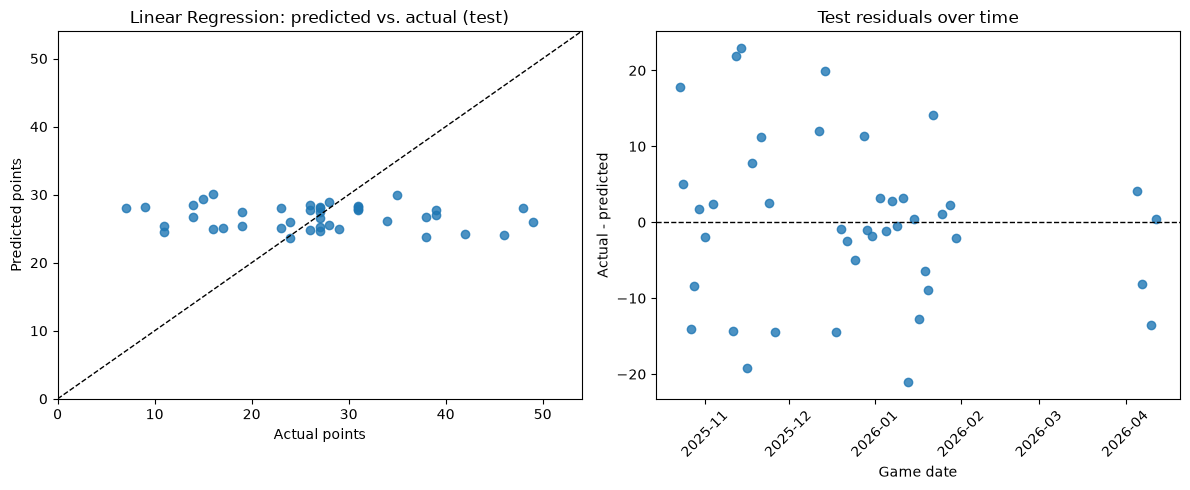

In [22]:
results = test[['player_id', 'player_name', 'game_date', TARGET]].assign(predicted=test_pred)
results['residual'] = results[TARGET] - results['predicted']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

lims = [0, max(results[TARGET].max(), results['predicted'].max()) + 5]
ax1.scatter(results[TARGET], results['predicted'], alpha=0.8)
ax1.plot(lims, lims, 'k--', linewidth=1)
ax1.set(xlim=lims, ylim=lims, xlabel='Actual points', ylabel='Predicted points',
        title='Linear Regression: predicted vs. actual (test)')

ax2.scatter(results['game_date'], results['residual'], alpha=0.8)
ax2.axhline(0, color='k', linestyle='--', linewidth=1)
ax2.set(xlabel='Game date', ylabel='Actual - predicted', title='Test residuals over time')
ax2.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

## Error per player

The test set has a single player, so the per-player test table has only one row. The cross-validation predictions cover all players, so they show which players the model handles worst. High-volume, high-variance scorers usually have the largest errors.

In [23]:
def per_player_errors(frame):
    return (
        frame.groupby(['player_id', 'player_name'])
        .apply(lambda g: pd.Series({'n': len(g), **evaluate(g[TARGET], g['predicted'])}), include_groups=False)
        .astype({'n': int})
        .sort_values('MAE', ascending=False)
        .round(3)
    )


print('Test:')
display(per_player_errors(results))

if oof is not None:
    cv_per_player = per_player_errors(oof)
    print(f'Cross-validation: worst 20 of {len(cv_per_player)} players by MAE')
    display(cv_per_player.head(20))

Test:


,,n,MAE,RMSE,R2
player_id,player_name,,,,
201939,Stephen Curry,42,8.123,10.64,-0.066


Cross-validation: worst 20 of 84 players by MAE


,,n,MAE,RMSE,R2
player_id,player_name,,,,
201939,Stephen Curry,57,8.025,10.468,-0.052
1630162,Anthony Edwards,63,7.967,10.061,-0.032
1628973,Jalen Brunson,49,7.649,9.719,-0.077
1629029,Luka Dončić,36,7.603,8.824,-0.033
203999,Nikola Jokić,58,7.518,9.905,-0.032
1626164,Devin Booker,59,7.467,8.751,-0.076
1628384,OG Anunoby,58,7.199,8.472,0.007
1629027,Trae Young,60,6.791,8.216,-0.054
203078,Bradley Beal,44,6.730,8.080,-0.064


## Notes

- The test split here is one player's 2025-26 season, so the test metrics are about that player and should not be read as general accuracy. The cross-validation scores, which cover 84 players, are the better guide to how the model does across the league.
- For a multi-player test set, re-run `ml/EDA/feature_engineering.ipynb` so that `time_split` is applied to the 2024-25 season only. Then re-run `prediction_baseline.ipynb` and this notebook on the result, so the comparison stays fair.
- Every feature is computed from earlier games only, and the train/test split is by date, so the test score is not inflated by leakage.
- To try more features, add their column names to `CONTEXT_FEATURES` in the Config cell, as long as they are known before the game.

## Save the model (optional)

Set `SAVE_MODEL = True` in the Config cell to write the fitted pipeline and its metrics to `ml/models/artifacts/`.

In [24]:
if SAVE_MODEL:
    import joblib

    ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
    model_path = ARTIFACT_DIR / 'linear_regression_points.joblib'
    metrics_path = ARTIFACT_DIR / 'linear_regression_metrics.csv'
    joblib.dump({'pipeline': pipeline, 'features': FEATURES, 'target': TARGET}, model_path)
    lr_results.to_csv(metrics_path, index=False)
    print(f'Wrote {model_path} and {metrics_path}')
else:
    print('SAVE_MODEL is False; no files written')

Wrote /Users/swayamshree/Desktop/Capstone Project/CPSC491-02Group8SportsBetting/ml/models/artifacts/linear_regression_points.joblib and /Users/swayamshree/Desktop/Capstone Project/CPSC491-02Group8SportsBetting/ml/models/artifacts/linear_regression_metrics.csv
